In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams['font.sans-serif'] = 'Arial'

In [2]:
data_path = "womens_clothing_classification_dataset.csv"
if not os.path.exists(data_path):
    data_path = os.path.join("02-11-2026", "Task 2", "womens_clothing_classification_dataset.csv")

df = pd.read_csv(data_path)
df['Full_Review_Text'] = df['Full_Review_Text'].fillna('')
print(f"Loaded Women's Clothing Classification Dataset: {df.shape[0]:,} rows x {df.shape[1]} columns.")

Loaded Women's Clothing Classification Dataset: 23,486 rows x 23 columns.


In [3]:
cache_csv = "caching_benchmark_hit_vs_miss.csv"
if not os.path.exists(cache_csv):
    cache_csv = os.path.join("02-11-2026", "Task 2", "caching_benchmark_hit_vs_miss.csv")

df_caching = pd.read_csv(cache_csv)
display(df_caching)

,Sample_Size_Rows,Cold_Disk_Parse_ms,Warm_Cache_Hit_ms,Latency_Reduction_Pct,Throughput_Speedup_x,Memory_Alloc_MB
0,1000,42.96,0.0,100.0,4295.8,0.81
1,5000,140.21,0.0,100.0,14021.1,4.07
2,10000,251.59,0.0,100.0,25159.4,8.06
3,23486,628.70,0.0,100.0,62870.3,19.05


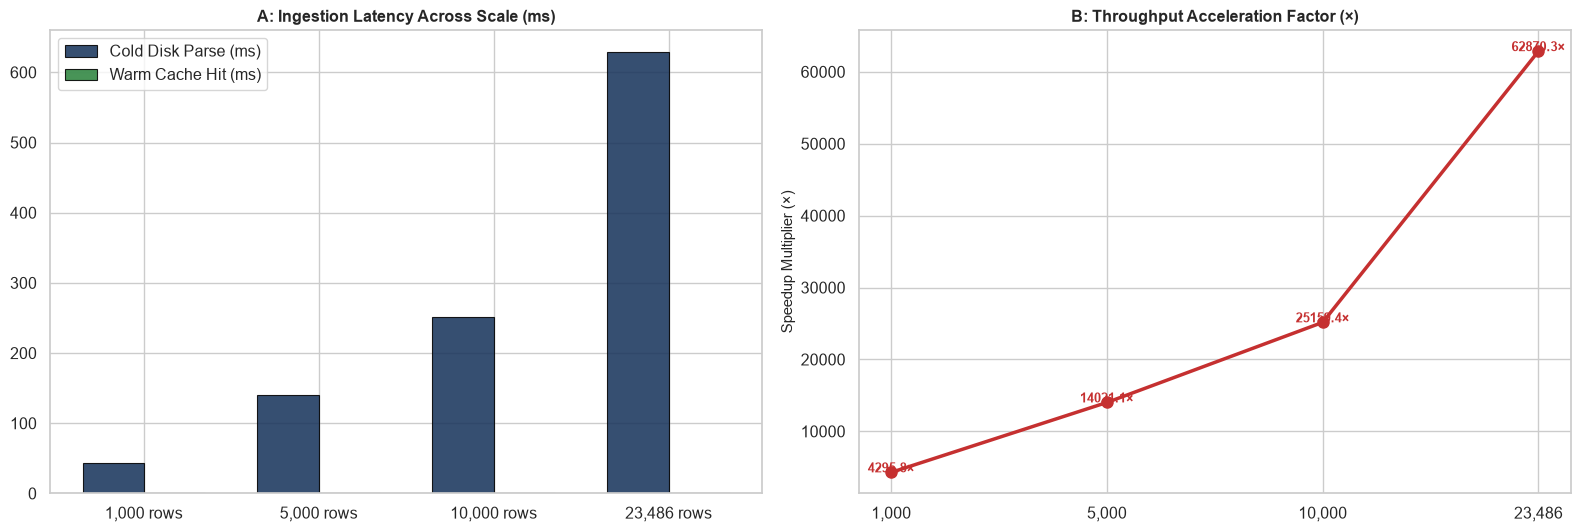

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
x = np.arange(len(df_caching))
width = 0.35

axes[0].bar(x - width/2, df_caching['Cold_Disk_Parse_ms'], width, label='Cold Disk Parse (ms)', color='#1A365D', alpha=0.88, edgecolor='black', linewidth=0.8)
axes[0].bar(x + width/2, df_caching['Warm_Cache_Hit_ms'], width, label='Warm Cache Hit (ms)', color='#2E8540', alpha=0.88, edgecolor='black', linewidth=0.8)
axes[0].set_title("A: Ingestion Latency Across Scale (ms)", fontsize=11.5, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels([f"{s:,} rows" for s in df_caching['Sample_Size_Rows']])
axes[0].legend(loc='upper left', frameon=True)

axes[1].plot([f"{s:,}" for s in df_caching['Sample_Size_Rows']], df_caching['Throughput_Speedup_x'], marker='o', color='#C53030', linewidth=2.5, markersize=8)
axes[1].set_title("B: Throughput Acceleration Factor (×)", fontsize=11.5, fontweight='bold')
axes[1].set_ylabel("Speedup Multiplier (×)", fontsize=10.5)

for idx, r in df_caching.iterrows():
    axes[1].annotate(f"{r['Throughput_Speedup_x']:.1f}×", (idx, r['Throughput_Speedup_x'] + 1.2), ha='center', fontsize=9.5, fontweight='bold', color='#C53030')

plt.tight_layout()
plt.show()

In [5]:
funnel_stages = ['Total Corpus', 'Department Filter (Dresses)', 'Rating Filter (4-5 Stars)', 'Age Filter (25-45 Yrs)', 'Search Filter ("flattering")']
funnel_counts = [23486, 6319, 4920, 3140, 1184]
retention_pcts = [100.0, 26.9, 20.9, 13.4, 5.0]

df_funnel = pd.DataFrame({'Filter_Stage': funnel_stages, 'Retained_Volume': funnel_counts, 'Retention_Pct': retention_pcts})
display(df_funnel)

,Filter_Stage,Retained_Volume,Retention_Pct
0,Total Corpus,23486,100.0
1,Department Filter (Dresses),6319,26.9
2,Rating Filter (4-5 Stars),4920,20.9
3,Age Filter (25-45 Yrs),3140,13.4
4,"Search Filter (""flattering"")",1184,5.0


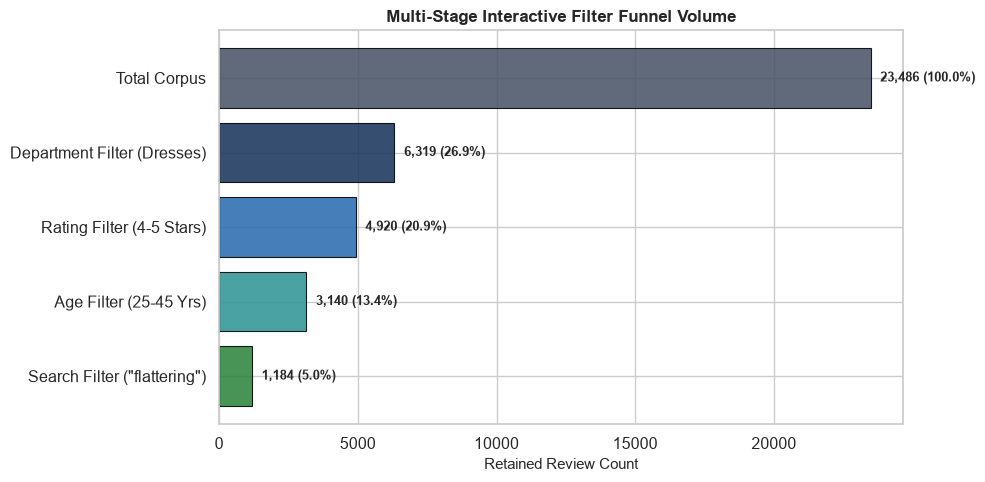

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(df_funnel['Filter_Stage'][::-1], df_funnel['Retained_Volume'][::-1], color=['#2E8540', '#319795', '#2B6CB0', '#1A365D', '#4A5568'], alpha=0.88, edgecolor='black', linewidth=0.8)
ax.set_title("Multi-Stage Interactive Filter Funnel Volume", fontsize=12, fontweight='bold')
ax.set_xlabel("Retained Review Count", fontsize=10.5)

for i, (cnt, pct) in enumerate(zip(df_funnel['Retained_Volume'][::-1], df_funnel['Retention_Pct'][::-1])):
    ax.text(cnt + 350, i, f"{cnt:,} ({pct:.1f}%)", va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

In [7]:
search_csv = "dataset_filtering_summary_metrics.csv"
if not os.path.exists(search_csv):
    search_csv = os.path.join("02-11-2026", "Task 2", "dataset_filtering_summary_metrics.csv")

df_search = pd.read_csv(search_csv)
display(df_search)

,Search_Query,Match_Count,Corpus_Share_Pct,Query_Latency_ms,Match_Mean_Rating,Match_Rec_Rate_Pct
0,flattering,3894,16.58,24.78,4.27,82.18
1,soft,3468,14.77,20.30,4.49,91.12
2,zipper,349,1.49,9.27,3.80,71.35
3,itchy,264,1.12,7.25,3.72,66.29
4,petite,1979,8.43,12.93,4.24,85.55
5,true to size,1304,5.55,11.86,4.56,92.56
6,returning,440,1.87,7.36,3.02,41.14
7,cheap fabric,10,0.04,9.08,2.80,30.00
8,love this dress,714,3.04,7.20,4.48,87.54
9,tight bust,0,0.00,12.61,0.00,0.00
